# Replicações independentes e cenários difíceis

Três novas seeds (101, 202 e 303), cada uma com cinco cenários pareados. Isso representa três realizações independentes com cinco variações cada, não quinze amostras independentes. Os três modelos, seus pré-processadores e seus limiares originais ficam congelados.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ml").is_dir() and (p / "sql").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from ml.data import load_tables
from ml.plotting import configure_style, style_table, save_figure
from ml.config import REPORTS, ARTIFACTS
get_ipython().run_line_magic("matplotlib", "inline")
configure_style()
pd.set_option("display.max_columns", 40)

import json
DESTINATION = ROOT / "ml/reports/robustness/rodada_01"
assert (DESTINATION / "protocolo_registrado.json").exists(), "Execute primeiro python -m ml.robustness.run"


## Regras definidas antes dos resultados

- **Original:** regras do gerador existente, com nova seed.
- **Sutis:** fatores 1,1–1,3 ou 0,7–0,9, mantendo as transações selecionadas como anomalia.
- **Extremos legítimos:** cerca de 5% dos normais têm picos 1,5–3,5 e continuam com rótulo normal.
- **Regime:** 30% dos parceiros passam a operar em nível 1,8 vezes maior a partir de julho/2025.
- **Combinado:** sutis + ruído legítimo extra sigma log 0,25 + extremos + regime.

As sementes para ruído, eventos legítimos, regime e fatores são separadas. A avaliação usa apenas julho–dezembro/2025 e históricos de dias anteriores da nova fonte. Não há recalibração nos desafios. São simulações controladas, sem alegação de representar a frequência real desses eventos.

In [2]:
metrics = pd.read_csv(DESTINATION / "metricas_desafios.csv")
selected = json.loads((REPORTS / "selecao_validacao.json").read_text(encoding="utf-8"))["selecionado"]
chosen = metrics[metrics.modelo == selected]
summary = chosen.groupby("cenario").agg(AP=("average_precision", "mean"), Precisão=("precision", "mean"), Recall=("recall", "mean"), F1=("f1", "mean"), F1_mínimo=("f1", "min"), F1_máximo=("f1", "max"), Falsos_alertas_normais=("fpr_normais", "mean")).reset_index()
display(style_table(summary.round(4)))


cenario,AP,Precisão,Recall,F1,F1_mínimo,F1_máximo,Falsos_alertas_normais
combinado,0.071100,0.076900,0.151800,0.102000,0.093900,0.110700,0.125700
extremos_legitimos,0.634300,0.585800,0.867600,0.699400,0.694700,0.708100,0.042200
mudanca_regime,0.884300,0.477200,0.921600,0.628800,0.617800,0.639200,0.069600
original,0.984800,0.986400,0.952100,0.969000,0.958700,0.977100,0.000900
sutis,0.406700,0.536200,0.313900,0.395800,0.377200,0.422100,0.018700


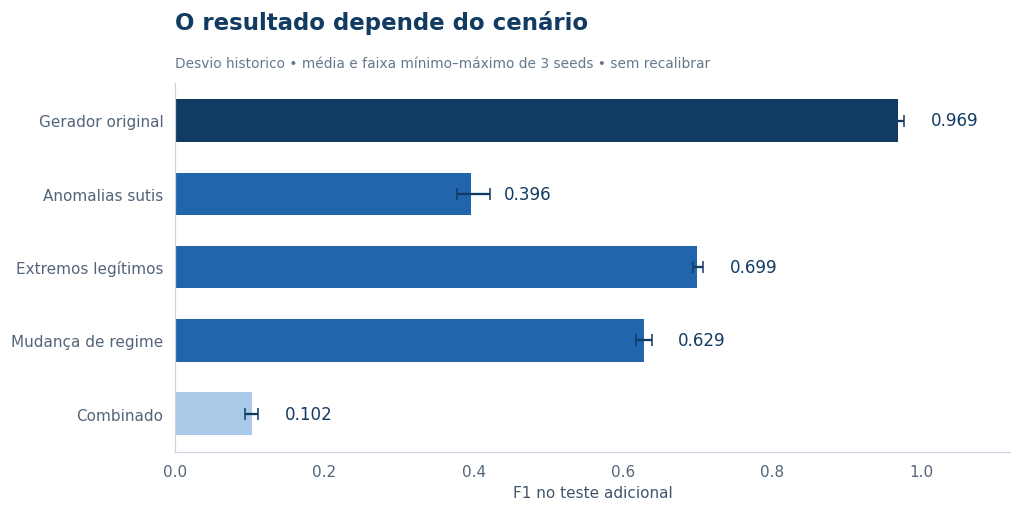

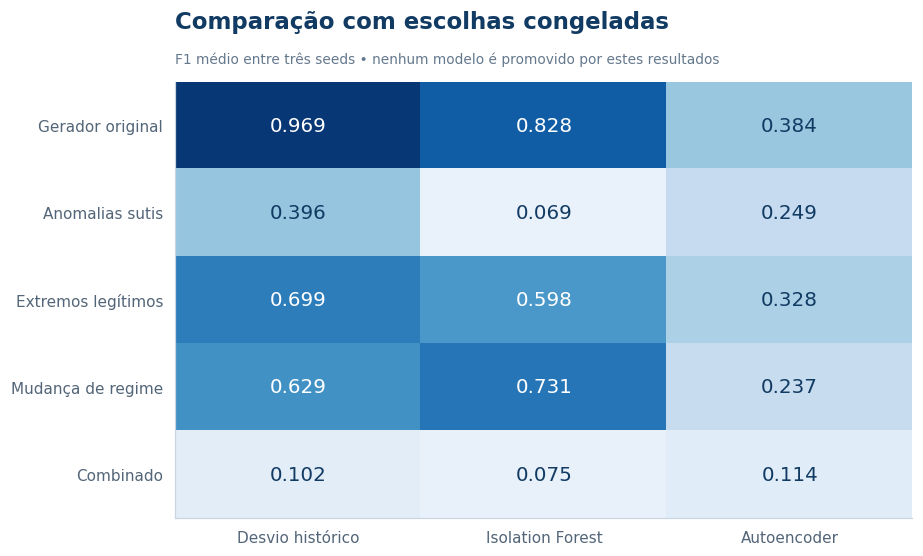

In [3]:
from ml.robustness.report import make_figures
figures = make_figures(DESTINATION)
for figure in figures[:2]:
    display(figure)
for figure in figures:
    plt.close(figure)


## Limite de observabilidade

Um pico legítimo e uma adulteração podem ter o mesmo valor e o mesmo histórico disponível. Sem uma variável que explique o evento legítimo, não existe garantia de distingui-los usando só esses atributos. Esse stress test questiona o alvo e as informações disponíveis, além do algoritmo.

Uma AP ainda alta acompanhada de queda no F1 pode indicar perda de calibração do limiar. Recalibrar exigiria outra validação; os desafios atuais não foram usados para esse ajuste.

In [4]:
detail = metrics.groupby(["cenario", "modelo"])[["average_precision", "f1", "fpr_normais", "fpr_extremos_legitimos", "fpr_normais_regime"]].mean().reset_index()
display(style_table(detail.round(4)))


cenario,modelo,average_precision,f1,fpr_normais,fpr_extremos_legitimos,fpr_normais_regime
combinado,Autoencoder,0.071300,0.114300,0.207100,0.422100,0.428000
combinado,Desvio historico,0.071100,0.102000,0.125700,0.820100,0.240500
combinado,Isolation Forest,0.068300,0.074900,0.084600,0.700100,0.149600
extremos_legitimos,Autoencoder,0.275200,0.328300,0.049400,0.345600,0.000000
extremos_legitimos,Desvio historico,0.634300,0.699400,0.042200,0.828700,0.000000
extremos_legitimos,Isolation Forest,0.502300,0.597900,0.039800,0.662500,0.000000
mudanca_regime,Autoencoder,0.164600,0.237000,0.161600,0.000000,0.508300
mudanca_regime,Desvio historico,0.884300,0.628800,0.069600,0.000000,0.257300
mudanca_regime,Isolation Forest,0.749100,0.731000,0.023500,0.000000,0.073800
original,Autoencoder,0.343600,0.384000,0.037100,0.000000,0.000000
